# Exercise 3: Convolutions, Autoencoders & Variational Autoencoders

# Prerequisites
Please install Python and the required libraries for this exercise, or do it in Google Colab. We use [PyTorch](https://pytorch.org/get-started/locally/), as in the lecture.

Besides PyTorch you need the `medmnist` package (`pip install medmnist`, or uncomment the first line of the next cell in Colab).

The import statements of the solution we prepared are specified below, however feel free to use any other library.

## Data
We work with **BloodMNIST** (Yang et al., *MedMNIST v2*, Scientific Data 2023). It contains ~17,000 microscope images of single blood cells from peripheral blood smears of healthy donors, each labelled with one of 8 cell types: basophil, eosinophil, erythroblast, immature granulocyte, lymphocyte, monocyte, neutrophil and platelet. Counting these cell types (the *differential blood count*) is one of the most common tests in the clinic, e.g. to detect infections or to screen for leukaemia, and is increasingly automated with deep learning.

The images are downscaled to 28 × 28 pixels with 3 colour channels (RGB). The colour comes from the staining of the smear and carries information about the cell type.

**Total: 20 points.** Questions are part of the points, answer them in 1–3 sentences in the markdown cells.

In [46]:
# Group 7: Ihsane Darssi, Christine Engelmann, Shang La

In [2]:
%pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 2.8 MB/s  0:00:00m 2.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [medmnist]━━ 2/4 [torchvision]
Note: you may need to restart the kernel to use updated packages.


In [3]:
# !pip install medmnist
# These are the libraries that we used - feel free to use others if you want
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from medmnist import BloodMNIST

torch.manual_seed(0)
np.random.seed(0)

# 1)
Load the data and get to know it. (1 point)

- Plot one example image of each of the 8 cell types, with the cell type as title.
- How many images of each cell type are there in the training set (a bar plot is enough)? Is the dataset balanced?

In [4]:
# Load data (downloads ~35 MB the first time)
train_set = BloodMNIST(split="train", download=True, size=28)
test_set = BloodMNIST(split="test", download=True, size=28)

X_train_img = train_set.imgs          # shape (n_images, 28, 28, 3), values 0-255
y_train = train_set.labels.ravel()    # cell type 0-7
X_test_img = test_set.imgs
y_test = test_set.labels.ravel()

class_names = ["basophil", "eosinophil", "erythroblast", "immature granulocyte",
               "lymphocyte", "monocyte", "neutrophil", "platelet"]
print(X_train_img.shape, X_test_img.shape)

100%|█████████████████████████████████████████████████████████████████████████████| 35.5M/35.5M [00:18<00:00, 1.97MB/s]


(11959, 28, 28, 3) (3421, 28, 28, 3)


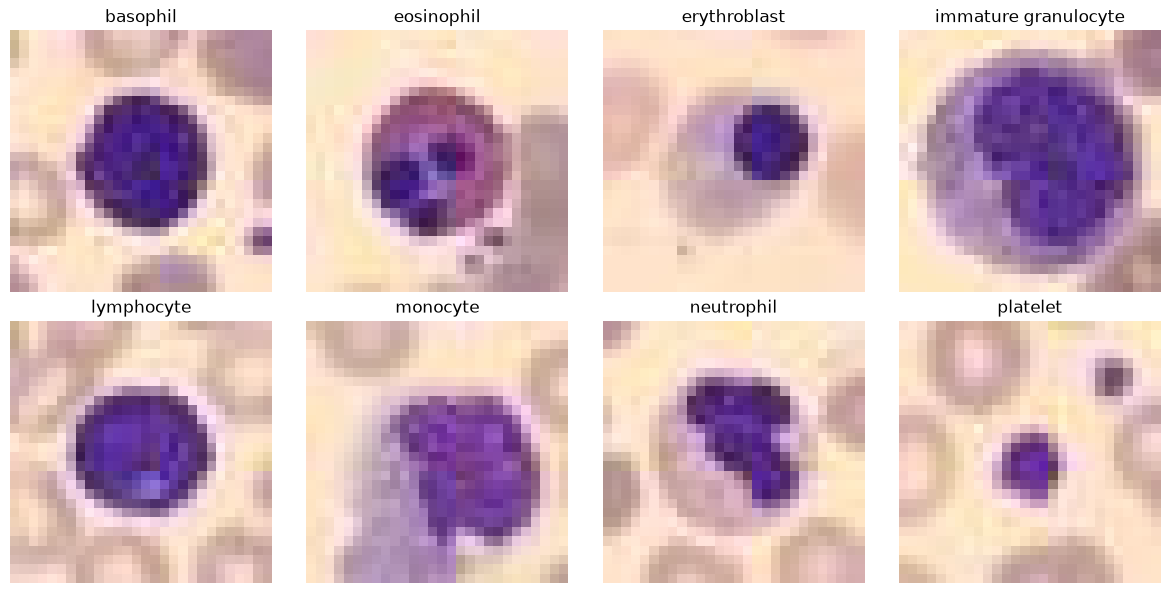

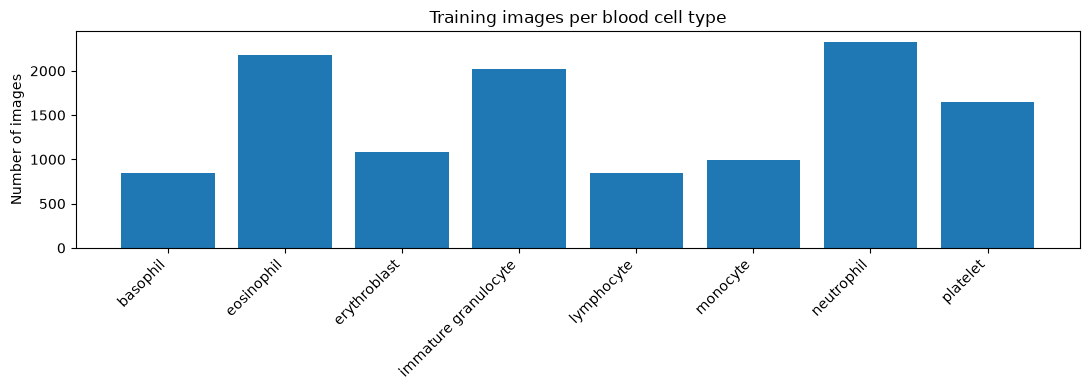

Counts per cell type: [ 852 2181 1085 2026  849  993 2330 1643]


In [6]:
# Plot one example per cell type
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(8):
    idx = np.where(y_train == i)[0][0]
    axes.flat[i].imshow(X_train_img[idx])
    axes.flat[i].set_title(class_names[i])
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

# Number of images per cell type
counts = np.bincount(y_train.flatten())

plt.figure(figsize=(11, 4))
plt.bar(class_names, counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Training images per blood cell type")
plt.tight_layout()
plt.show()

print("Counts per cell type:", counts)

*Your answer:* In total the dataset has 11,959 images, which belong to 8 different blood cell types. The dataset is not however balanced, seeing as class counts ranging from 849 to 2330 images. 

# 2)
Convolutions and pooling by hand. (7 points)

**How a convolution is computed.** A convolution takes a small matrix of weights, the *kernel*, and slides it over the image:

1. Place the kernel on the top-left corner of the image.
2. Multiply each kernel weight with the pixel below it and **sum** all these products. The sum is one value of the output.
3. Move the kernel `stride` pixels to the right and repeat. At the end of a row, go back to the left and move `stride` pixels down.

Example with a 4 × 4 image $x$ and a 2 × 2 kernel $k$ (stride 1, no padding):

$$x = \begin{pmatrix} \mathbf{1} & \mathbf{2} & 0 & 1 \\ \mathbf{0} & \mathbf{1} & 3 & 1 \\ 2 & 1 & 0 & 0 \\ 1 & 0 & 1 & 2 \end{pmatrix} \qquad k = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} \qquad out = \begin{pmatrix} \mathbf{0} & -1 & -1 \\ -1 & 1 & 3 \\ 2 & 0 & -2 \end{pmatrix}$$

The first output value comes from the bold patch: $1\cdot1 + 2\cdot0 + 0\cdot0 + 1\cdot(-1) = 0$. One step to the right, the patch is $\begin{pmatrix} 2 & 0 \\ 1 & 3 \end{pmatrix}$, which gives $2 - 3 = -1$, and so on.

- **Stride:** with stride 2 the kernel jumps 2 pixels each time, so only every second position is computed and the output gets smaller: here $\begin{pmatrix} 0 & -1 \\ 2 & -2 \end{pmatrix}$.
- **Padding:** `pad` rows/columns of zeros are added around the image before sliding, so that the kernel also fits on the border pixels and the output does not shrink as much.

## a) Convolution (3 points)
Implement this as a function `conv(x, kernel, stride, pad)`:

- `x`: a two-dimensional array of size `(H, W)`.
- `kernel`: convolution kernel of size `(K, K)`.
- `stride`: the step the kernel moves each time, 0 < stride ≤ min(H, W).
- `pad`: number of zero rows/columns added to each side of the array, pad ≥ 0 (`np.pad` can help).

The function should return `out`, the result of convolving `x`, with dimensions `(H', W')`:

$$H' = \left\lfloor \frac{H + 2\cdot pad - K}{stride} \right\rfloor + 1 \qquad W' = \left\lfloor \frac{W + 2\cdot pad - K}{stride} \right\rfloor + 1$$

Use loops and numpy, not a library convolution function.

In [7]:
# Define convolution function
def conv(x, kernel, stride=1, pad=0):
    # Add zero padding around the image
    x = np.pad(x, pad_width=pad, mode="constant")

    # Get image and kernel dimensions
    H, W = x.shape
    kH, kW = kernel.shape

    # Calculate output dimensions
    out_H = (H - kH) // stride + 1
    out_W = (W - kW) // stride + 1

    # Create an empty output array
    out = np.zeros((out_H, out_W))

    # Slide the kernel over the image
    for i in range(out_H):
        for j in range(out_W):
            patch = x[i*stride:i*stride+kH,
                      j*stride:j*stride+kW]
            out[i, j] = np.sum(patch * kernel)

    return out

In [8]:
# Test your function on the example above
x_ex = np.array([[1, 2, 0, 1], [0, 1, 3, 1], [2, 1, 0, 0], [1, 0, 1, 2]])
k_ex = np.array([[1, 0], [0, -1]])
print(conv(x_ex, k_ex, stride=1, pad=0))   # should be [[ 0. -1. -1.] [-1.  1.  3.] [ 2.  0. -2.]]
print(conv(x_ex, k_ex, stride=2, pad=0))   # should be [[ 0. -1.] [ 2. -2.]]

# ... and on a slightly bigger one
a = np.arange(9).reshape((3, 3))
M = np.block([[a, a], [a, a]])
print(M)
print(conv(M, np.ones((2, 2)), stride=2, pad=0))   # should be [[ 8. 10. 12.] [14. 16. 18.] [20. 22. 24.]]
print(conv(M, np.ones((3, 3)), stride=1, pad=1).shape)  # should be (6, 6)

[[ 0. -1. -1.]
 [-1.  1.  3.]
 [ 2.  0. -2.]]
[[ 0. -1.]
 [ 2. -2.]]
[[0 1 2 0 1 2]
 [3 4 5 3 4 5]
 [6 7 8 6 7 8]
 [0 1 2 0 1 2]
 [3 4 5 3 4 5]
 [6 7 8 6 7 8]]
[[ 8. 10. 12.]
 [14. 16. 18.]
 [20. 22. 24.]]
(6, 6)


## Sobel filters
A **Sobel filter** is a classic hand-designed kernel that detects **edges**. An edge is a place where the brightness changes quickly, i.e. where the derivative of the image is large. The Sobel kernel approximates this derivative:

$$S_x = \begin{pmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{pmatrix} \qquad S_y = \begin{pmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{pmatrix} = S_x^T$$

- Each row of $S_x$ computes *right neighbour − left neighbour*, a discrete derivative in x-direction. The rows are weighted 1-2-1, which averages over three rows and makes the filter less sensitive to noise.
- $S_x$ therefore responds to **vertical** edges (brightness changes from left to right), $S_y$ to **horizontal** edges. In flat regions both give 0. The sign tells the direction of the change (dark → bright or bright → dark).
- Combining both gives the edge strength in any direction: $G = \sqrt{G_x^2 + G_y^2}$, where $G_x$ and $G_y$ are the convolution results.

In a CNN, the kernels are not designed by hand but *learned*, and the first layer of a trained CNN often ends up with edge detectors very similar to Sobel filters.

Run the next cell to see the filter on an image with a single vertical edge (dark left half, bright right half):

In [9]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = sobel_x.T

step = np.zeros((5, 5))
step[:, 3:] = 1
print(step)
print(conv(step, sobel_x, stride=1, pad=0))   # large values where the edge is
print(conv(step, sobel_y, stride=1, pad=0))   # no horizontal edge -> all 0

[[0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]]
[[0. 4. 4.]
 [0. 4. 4.]
 [0. 4. 4.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


## b) Edges of a blood cell (1 point)
Convert one cell image to grayscale (average over the colour channels and divide by 255). Apply both Sobel filters (stride 1, padding 1) and compute the edge strength $G$. Plot the grayscale image, $G_x$, $G_y$ and $G$ next to each other. (The bright frame at the border of $G$ is an artefact of the zero padding: the image suddenly "drops" to 0 there.)

Original image shape: (28, 28, 3)
Grayscale image shape: (28, 28)


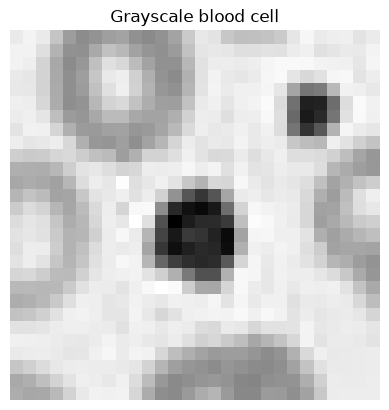

Sobel X shape: (28, 28)
Sobel Y shape: (28, 28)


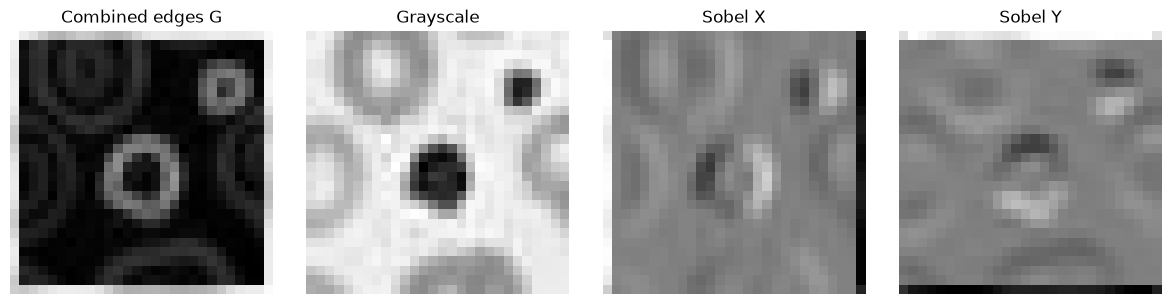

In [13]:
img = X_train_img[0]
# Convert to grayscale
gray = img.mean(axis=2) / 255

print("Original image shape:", img.shape)
print("Grayscale image shape:", gray.shape)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale blood cell")
plt.axis("off")
plt.show()
# Apply Sobel filters
edges_x = conv(gray, sobel_x, stride=1, pad=1)
edges_y = conv(gray, sobel_y, stride=1, pad=1)

print("Sobel X shape:", edges_x.shape)
print("Sobel Y shape:", edges_y.shape)

G = np.sqrt(edges_x**2 + edges_y**2)
# Display results
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(G, cmap="gray")
axes[0].set_title("Combined edges G")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")

axes[2].imshow(edges_x, cmap="gray")
axes[2].set_title("Sobel X")

axes[3].imshow(edges_y, cmap="gray")
axes[3].set_title("Sobel Y")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## c) Compare with PyTorch (1 point)
In a CNN you would not write the convolution yourself but use a layer of the library, which calls `torch.nn.functional.conv2d`. Apply `sobel_x` to the same grayscale image with `F.conv2d` (stride 1, padding 1) and check that you get the same result as with your `conv` (e.g. with `np.allclose`). Note that `F.conv2d` expects tensors of shape `(batch, channels, H, W)` for the image and `(out_channels, in_channels, K, K)` for the kernel.

**Question:** Using the formula from a), what output size do you expect for the 28 × 28 image and the 3 × 3 Sobel kernel (i) with stride 1 and padding 1, (ii) with stride 1 and no padding, (iii) with stride 2 and padding 1? Check your answers with `conv` or `F.conv2d`. What is the padding good for?

In [17]:
# Convert image and filter into PyTorch tensors
x_torch = torch.tensor(gray, dtype=torch.float32).reshape(1, 1, 28, 28)
k_torch = torch.tensor(sobel_x, dtype=torch.float32).reshape(1, 1, 3, 3)
# Apply sobel_x with F.conv2d and compare with your result
result_torch = F.conv2d(x_torch, k_torch, stride=1, padding=1)

# Compare with our own convolution function
print("PyTorch output shape:", result_torch.shape)
print("Same result?", np.allclose(result_torch.numpy().squeeze(), edges_x))
difference = np.abs(result_torch.numpy().squeeze() - edges_x)
# Check the output sizes
print("Stride 1, padding 1:", conv(gray, sobel_x, stride=1, pad=1).shape)
print("Stride 1, padding 0:", conv(gray, sobel_x, stride=1, pad=0).shape)
print("Stride 2, padding 1:", conv(gray, sobel_x, stride=2, pad=1).shape)



PyTorch output shape: torch.Size([1, 1, 28, 28])
Same result? False
Stride 1, padding 1: (28, 28)
Stride 1, padding 0: (26, 26)
Stride 2, padding 1: (14, 14)


*Your answer:* For stride 1 with padding 1 the expected output size is 28 x 28. For stride 1 without padding it is 26 x 26 and 14 x 14 for stride 2 and padding 1.
The results using conv and PyTorch's F.conv2d are nearly identical, having only a very small difference due to numerical precision.

Padding is good for preserving the original image size as it allows the kernel to process the image borders.

## d) Max pooling (1 point)
Implement `max_pool(x, size)`: split the array into non-overlapping `size × size` blocks (stride = size, no padding) and keep the maximum of each block. Apply it with `size=2` and `size=4` to the edge strength $G$ from b) and plot the results.

Original: (28, 28)
Pooling size 2: (14, 14)
Pooling size 4: (7, 7)


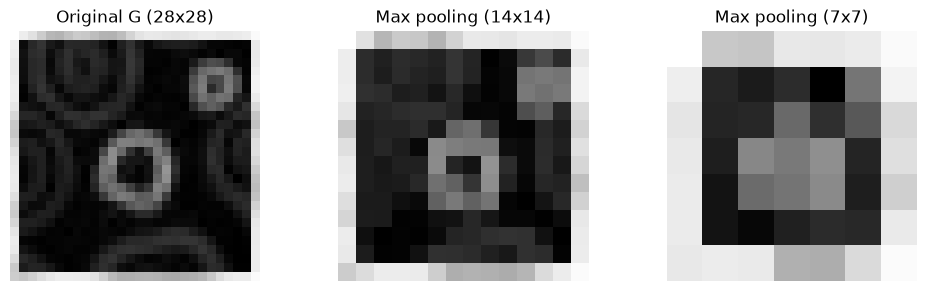

In [19]:
def max_pool(x, size):
    H, W = x.shape

    # Calculate the output size
    out_H = H // size
    out_W = W // size

    # Create an empty output array
    out = np.zeros((out_H, out_W))

    # Go through each block
    for i in range(out_H):
        for j in range(out_W):
            block = x[i*size:(i+1)*size,
                      j*size:(j+1)*size]

            # Keep the largest value
            out[i, j] = np.max(block)

    return out

# Apply to G and plot
# Apply max pooling
G_pool2 = max_pool(G, size=2)
G_pool4 = max_pool(G, size=4)

# Check the sizes
print("Original:", G.shape)
print("Pooling size 2:", G_pool2.shape)
print("Pooling size 4:", G_pool4.shape)

# Display the results
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

axes[0].imshow(G, cmap="gray")
axes[0].set_title("Original G (28x28)")

axes[1].imshow(G_pool2, cmap="gray")
axes[1].set_title("Max pooling (14x14)")

axes[2].imshow(G_pool4, cmap="gray")
axes[2].set_title("Max pooling (7x7)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## e) Pooling and translation (1 point)
Move the cell image 1 pixel to the right (`np.roll(gray, 1, axis=1)`) and compute its edge strength $G_{shifted}$ again. Compare how much the result changes, before and after pooling, with the relative difference

$$\text{change} = \frac{\text{mean}(|A - B|)}{\text{mean}(|A|)}$$

once for $A = G$, $B = G_{shifted}$ and once for $A = $ `max_pool(G, 4)`, $B = $ `max_pool(G_shifted, 4)`.

**Question:** What do you observe? Explain how this relates to the translation invariance from the lecture, and why it is useful for classifying cells.

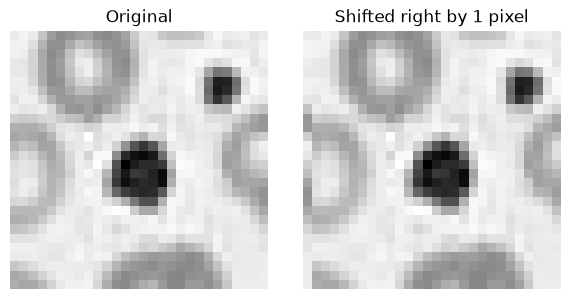

Difference before pooling: 0.21089536020075542
Difference before pooling: 0.21089536020075542
Difference after pooling: 0.15667098205868882


In [23]:
# Shift the image, compute the edge strength and compare before/after pooling
# Move the grayscale image 1 pixel to the right
gray_shifted = np.roll(gray, 1, axis=1)

# Display the original and shifted images
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(gray_shifted, cmap="gray")
axes[1].set_title("Shifted right by 1 pixel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()
# Apply Sobel filters to the shifted image
edges_x_shifted = conv(gray_shifted, sobel_x, stride=1, pad=1)
edges_y_shifted = conv(gray_shifted, sobel_y, stride=1, pad=1)

# Calculate the combined edge strength
G_shifted = np.sqrt(edges_x_shifted**2 + edges_y_shifted**2)

# Compare the edge strengths before pooling
difference_before = np.mean(np.abs(G - G_shifted))

print("Difference before pooling:", difference_before)
# Apply max pooling to both edge images
G_original_pooled = max_pool(G, size=2)
G_shifted_pooled = max_pool(G_shifted, size=2)

# Calculate the difference after pooling
difference_after = np.mean(
    np.abs(G_original_pooled - G_shifted_pooled)
)

print("Difference before pooling:", difference_before)
print("Difference after pooling:", difference_after)

*Your answer:* When moving the blood cell image 1 pixel to the right, the average difference between the original and shifted image was 0.2109. And after max pooling, the difference decreased to 0.1567, showing that it made the ege features less sensitive to a small shift.
It is useful because max pooling can offer translation invariance by keeping strong features eve when the positions are slightly changed.

# 3)
Train an autoencoder to reconstruct the blood cell images. (5 points)

The autoencoder is a fully connected network (like the MLP in exercise 2) on the flattened RGB images:
- **Encoder**: 2352 pixels (28 × 28 × 3) → 128 → 16 dimensions
- **Decoder**: 16 → 128 → 2352 pixels

Use ReLU activations in the hidden layers, and a sigmoid in the last layer so that the outputs are between 0 and 1 like the pixel values. The bottleneck (16 dimensions) forces the network to learn a compressed representation of the cells.

We provide the data preparation and the function `train_model`, which trains a model with the Adam optimizer and returns the training and test loss of every epoch. You don't have to change it. Training should take about a minute on a CPU.

In [20]:
# Flatten the images and scale them to [0, 1]
X_train = torch.tensor(X_train_img.reshape(len(X_train_img), -1) / 255.0, dtype=torch.float32)
X_test = torch.tensor(X_test_img.reshape(len(X_test_img), -1) / 255.0, dtype=torch.float32)
input_dim = X_train.shape[1]
print(X_train.shape, X_test.shape)


def train_model(model, loss_fn, X_train, X_test, epochs=20, batch_size=128, lr=1e-3):
    # loss_fn(model, x) must return the (scalar) loss of the model on the batch x
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            loss = loss_fn(model, xb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        train_losses.append(total / len(X_train))
        model.eval()
        with torch.no_grad():
            test_losses.append(loss_fn(model, X_test).item())
        print(f"epoch {epoch + 1:2d}  train loss {train_losses[-1]:.4f}  test loss {test_losses[-1]:.4f}")
    return train_losses, test_losses

torch.Size([11959, 2352]) torch.Size([3421, 2352])


## a) Model (2 points)
Complete the `Autoencoder` class: define `self.encoder` and `self.decoder` (e.g. with `nn.Sequential`), and the methods `forward` (input → reconstruction) and `encode` (input → 16-dimensional latent representation).

In [25]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, latent_dim=16):
        super().__init__()

        # Define self.encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )

        # Define self.decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction

    def encode(self, x):
        return self.encoder(x)


# Initialize model
ae = Autoencoder(input_dim)
# Test it first before training
# take one training image
sample = X_train[:1]

# Pass it through the autoencoder
reconstruction = ae(sample)

# Compress it using only the encoder
compressed = ae.encode(sample)

print("Input shape:", sample.shape)
print("Compressed shape:", compressed.shape)
print("Reconstructed shape:", reconstruction.shape)

Input shape: torch.Size([1, 2352])
Compressed shape: torch.Size([1, 16])
Reconstructed shape: torch.Size([1, 2352])


## b) Training (1 point)
Define the loss function `ae_loss(model, x)`, which returns the MSE between the reconstruction and the input, train the autoencoder for 20 epochs with `train_model` and plot the training and test loss over the epochs.

epoch  1  train loss 0.0076  test loss 0.0071
epoch  2  train loss 0.0070  test loss 0.0071
epoch  3  train loss 0.0070  test loss 0.0070
epoch  4  train loss 0.0069  test loss 0.0070
epoch  5  train loss 0.0069  test loss 0.0069
epoch  6  train loss 0.0068  test loss 0.0069
epoch  7  train loss 0.0068  test loss 0.0069
epoch  8  train loss 0.0068  test loss 0.0068
epoch  9  train loss 0.0067  test loss 0.0068
epoch 10  train loss 0.0067  test loss 0.0068
epoch 11  train loss 0.0067  test loss 0.0068
epoch 12  train loss 0.0067  test loss 0.0068
epoch 13  train loss 0.0067  test loss 0.0068
epoch 14  train loss 0.0067  test loss 0.0068
epoch 15  train loss 0.0066  test loss 0.0068
epoch 16  train loss 0.0066  test loss 0.0067
epoch 17  train loss 0.0066  test loss 0.0067
epoch 18  train loss 0.0066  test loss 0.0067
epoch 19  train loss 0.0066  test loss 0.0067
epoch 20  train loss 0.0066  test loss 0.0067


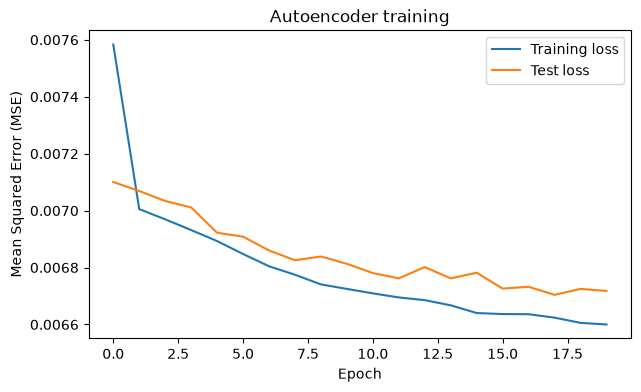

In [28]:
def ae_loss(model, x):
    reconstruction = model(x)
    return F.mse_loss(reconstruction, x)

# Train the model
train_losses, test_losses = train_model(
    ae, ae_loss, X_train, X_test, epochs=20
)
# Plot the loss curves
plt.figure(figsize=(7, 4))

plt.plot(train_losses, label="Training loss")
plt.plot(test_losses, label="Test loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Autoencoder training")
plt.legend()
plt.show()

## c) Reconstructions (1 point)
Reconstruct the test images and plot 8 original test images (top row) above their reconstructions (bottom row). Remember to reshape the vectors back to `(28, 28, 3)` images.

**Question:** What details of the cells are lost in the reconstructions, and why? Think about what the 16-dimensional bottleneck forces the network to do and what the MSE loss rewards.

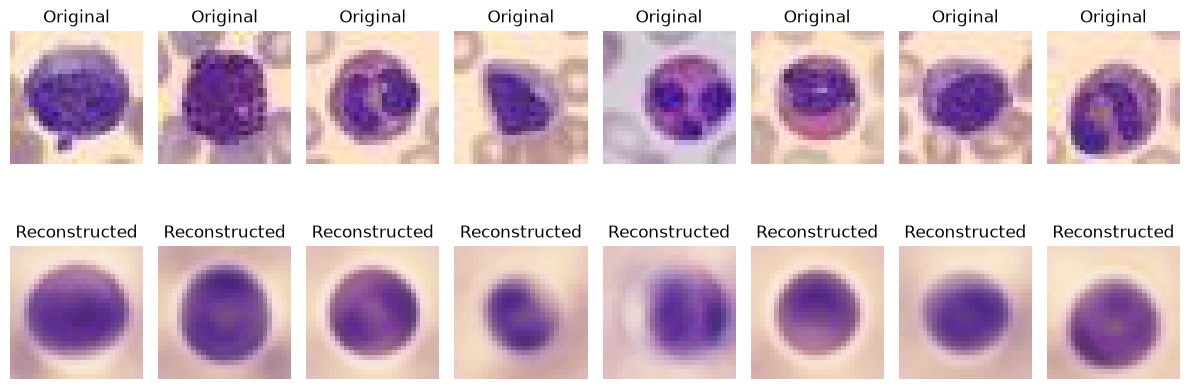

In [30]:
# Put the model in evaluation mode
ae.eval()

# Select test images
originals = X_test[:8]

# Reconstruct the test images
with torch.no_grad():
    reconstructed = ae(originals)

# Visualize original vs reconstructed
fig, axes = plt.subplots(2, 8, figsize=(12, 5))

for i in range(8):
    axes[0, i].imshow(originals[i].reshape(28, 28, 3).numpy())
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].reshape(28, 28, 3).numpy())
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

*Your answer:* Fine details and/or sharp cell boundaries as well as small textures seem to be lost, which is why the reconstructed images are slightly blurrier compared to the originals.
This might happen because the image is compressed into just 16 values by the autoencoder, resulting in the loss of some detail. The MSE loss also makes the model predict average pixel values, leading to potentially smoother and blurrier reconstruction images.

# 4)
Turn the autoencoder into a variational autoencoder (VAE). (7 points)

As in the lecture, the encoder of a VAE does not output one point z, but the mean $\mu$ and the standard deviation $\sigma$ of a normal distribution for each of the 16 latent variables. The latent representation z is then **sampled** from this distribution and decoded.

In practice the encoder outputs $\log\sigma^2$ instead of $\sigma$: a linear layer can output any number, but $\sigma$ must be positive. Taking the exponential, $\sigma = \exp\left(\tfrac{1}{2}\log\sigma^2\right)$, guarantees that, and it is numerically more stable.

**The reparameterization trick.** We cannot backpropagate through "draw z at random": the gradient of a random draw with respect to $\mu$ and $\sigma$ is not defined. So we move the randomness out of the way: first draw $\varepsilon \sim \mathcal{N}(0, 1)$, which does not depend on any parameter, and then compute

$$z = \mu + \sigma \cdot \varepsilon, \qquad \sigma = \exp\left(\tfrac{1}{2}\log\sigma^2\right)$$

This z has exactly the distribution $\mathcal{N}(\mu, \sigma^2)$, but now z is a simple (differentiable) function of $\mu$ and $\sigma$, so the gradients can flow back into the encoder. (`torch.randn_like` draws $\varepsilon$ with the right shape.)

**The loss.** The VAE loss is the reconstruction loss plus the Kullback-Leibler (KL) divergence that penalises $\mu$ and $\sigma$ for being different from 0 and 1. For normal distributions the KL divergence has a closed form, which you can use directly (sum over the 16 latent dimensions, mean over the samples of the batch):

$$KL = -\frac{1}{2}\sum_{j=1}^{16}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

For the reconstruction loss use the squared error **summed** over the 2352 pixels (and averaged over the samples of the batch), so that it has the same scale as the KL term.

## a) Reparameterization (1 point)
We provide the VAE class, which uses the same layer sizes as your autoencoder. Implement the method `reparameterize`.

In [35]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU())
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, input_dim), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + std * eps
        return z

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

## b) Loss (2 points)
Implement `vae_loss(model, x, beta=1.0)`, which returns reconstruction loss + `beta` × KL (the parameter `beta` lets us switch the KL term off in e)).

In [36]:
def vae_loss(model, x, beta=1.0):
    x_rec, mu, logvar = model(x)

    # Reconstruction loss
    rec_loss = ((x_rec - x) ** 2).sum(dim=1).mean()

    # KL divergence
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu**2 - torch.exp(logvar),
        dim=1
    ).mean()

    # Total loss
    return rec_loss + beta * kl_loss

## c) Training and generating new cells (1 point)
Train the VAE for 20 epochs with `train_model` (`loss_fn=vae_loss`). Then **generate** 8 new cell images: draw 8 random latent vectors $z \sim \mathcal{N}(0, I)$ (16-dimensional) and pass them through the decoder only. Plot them.

epoch  1  train loss 75.0897  test loss 52.1740
epoch  2  train loss 44.6625  test loss 40.8761
epoch  3  train loss 39.7071  test loss 38.5650
epoch  4  train loss 37.9737  test loss 37.2554
epoch  5  train loss 36.7381  test loss 36.2395
epoch  6  train loss 35.7726  test loss 35.3160
epoch  7  train loss 35.0419  test loss 34.7405
epoch  8  train loss 34.5930  test loss 34.3450
epoch  9  train loss 34.2511  test loss 34.3399
epoch 10  train loss 34.0568  test loss 33.9326
epoch 11  train loss 33.6530  test loss 33.5091
epoch 12  train loss 33.4019  test loss 33.2308
epoch 13  train loss 33.2709  test loss 33.5279
epoch 14  train loss 33.1268  test loss 33.3007
epoch 15  train loss 33.0345  test loss 32.9544
epoch 16  train loss 32.9890  test loss 33.3090
epoch 17  train loss 32.8587  test loss 32.7714
epoch 18  train loss 32.7949  test loss 32.6808
epoch 19  train loss 32.7313  test loss 32.6981
epoch 20  train loss 32.7294  test loss 32.6675


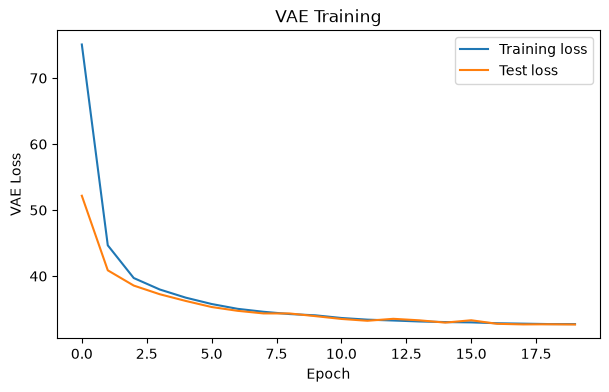

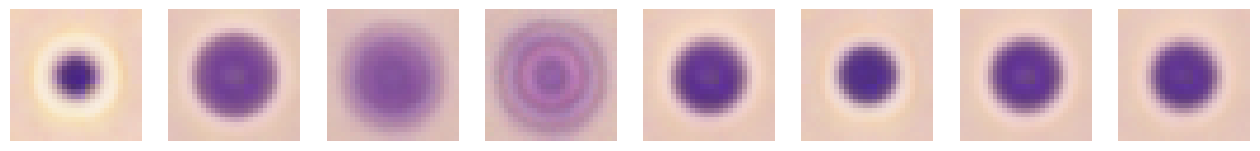

In [39]:
# Train the VAE
# Create the VAE
vae = VAE(input_dim)

# Train for 20 epochs
vae_train_losses, vae_test_losses = train_model(
    vae, vae_loss, X_train, X_test, epochs=20
)

plt.figure(figsize=(7, 4))

plt.plot(vae_train_losses, label="Training loss")
plt.plot(vae_test_losses, label="Test loss")

plt.xlabel("Epoch")
plt.ylabel("VAE Loss")
plt.title("VAE Training")
plt.legend()
plt.show()

# Generate new cells from random latent vectors
# Generate 8 random latent vectors
z = torch.randn(8, 16)

# Decode them into new images
vae.eval()
with torch.no_grad():
    new_cells = vae.decoder(z)

# Display the 8 generated images
fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for i in range(8):
    image = new_cells[i].reshape(28, 28, 3).numpy()
    axes[i].imshow(image)
    axes[i].axis("off")

plt.show()

## d) Comparing the latent spaces (2 points)
Encode the test images with the autoencoder (`encode`) and with the VAE (use $\mu$ as the latent representation). Reduce both 16-dimensional latent spaces to 2 dimensions with PCA and plot them side by side, coloured by cell type (with a legend).

**Question:** Do the cell types separate, although neither model ever saw the labels? How does the VAE latent space look different from the autoencoder latent space, and what part of the VAE causes this?

AE latent shape: (3421, 16)
VAE latent shape: (3421, 16)
AE PCA shape: (3421, 2)
VAE PCA shape: (3421, 2)


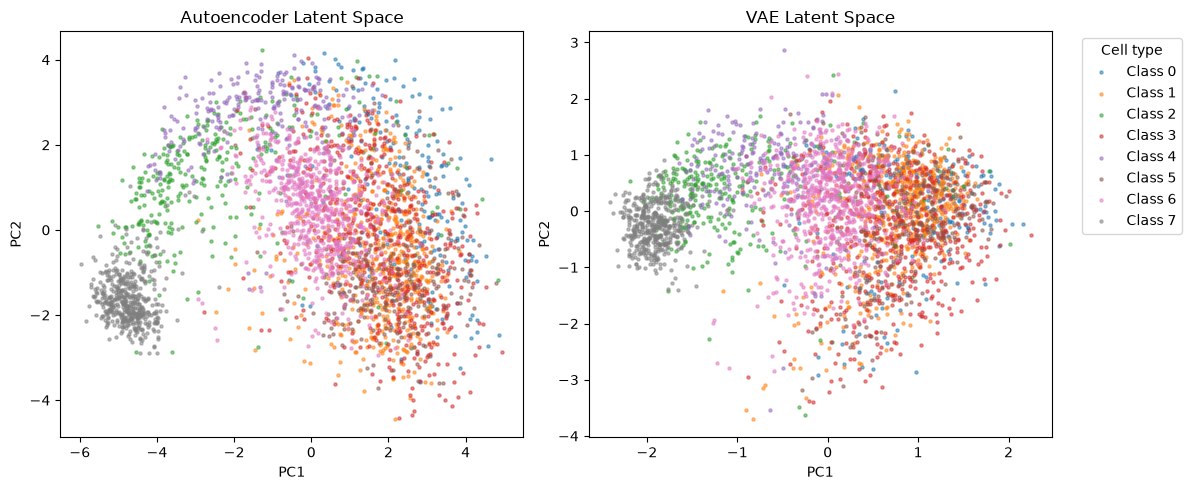

In [43]:
# Encode the test images
# Encode the test images
ae.eval()
vae.eval()

with torch.no_grad():
    # Regular autoencoder: 16 latent values
    z_ae = ae.encode(X_test).numpy()

    # VAE: use the mean as the latent representation
    mu, logvar = vae.encode(X_test)
    z_vae = mu.numpy()

print("AE latent shape:", z_ae.shape)
print("VAE latent shape:", z_vae.shape)
# PCA and plot
from sklearn.decomposition import PCA

# Reduce AE latent space from 16D to 2D
pca_ae = PCA(n_components=2)
z_ae_2d = pca_ae.fit_transform(z_ae)

# Reduce VAE latent space from 16D to 2D
pca_vae = PCA(n_components=2)
z_vae_2d = pca_vae.fit_transform(z_vae)

print("AE PCA shape:", z_ae_2d.shape)
print("VAE PCA shape:", z_vae_2d.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot both latent spaces
for ax, points, title in zip(
    axes,
    [z_ae_2d, z_vae_2d],
    ["Autoencoder", "VAE"]
):
    for cell_type in range(8):
        mask = y_test == cell_type

        ax.scatter(
            points[mask, 0],
            points[mask, 1],
            s=5,
            alpha=0.5,
            label=f"Class {cell_type}"
        )

    ax.set_title(title + " Latent Space")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

axes[1].legend(title="Cell type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

*Your answer:* What the Autoencodeer and VAE latent space plots have in common is that blood cells of the same type seem to have a tendency to form groups. Some overlap between classes can be seen too. This suggests both models have learned useful features distinguishing the different blood cell types even when no class labels were used during training.
After PCA the plots look fairly similar. But the VAE has an additional KL divergence term which makes thee latent space show more of a normal distribution. It makes it more suitable for generating new images by sampling random latent vectors.

## e) What does the KL term do? (1 point)
Train a second VAE with `beta=0`, i.e. without the KL term (you can pass `lambda model, x: vae_loss(model, x, beta=0)` as `loss_fn`). Generate 8 new cells from random $z \sim \mathcal{N}(0, I)$ again and compare them with the ones from c).

**Question:** What happens to the generated images without the KL term, and why?

epoch  1  train loss 58.5987  test loss 33.1179
epoch  2  train loss 30.5869  test loss 28.7687
epoch  3  train loss 27.5427  test loss 26.4840
epoch  4  train loss 25.6492  test loss 24.6707
epoch  5  train loss 23.9789  test loss 23.4334
epoch  6  train loss 22.8041  test loss 22.3512
epoch  7  train loss 21.8933  test loss 21.5203
epoch  8  train loss 21.2069  test loss 20.9799
epoch  9  train loss 20.6879  test loss 20.4696
epoch 10  train loss 20.3126  test loss 20.1184
epoch 11  train loss 19.9239  test loss 19.7791
epoch 12  train loss 19.5413  test loss 19.3222
epoch 13  train loss 19.0548  test loss 18.9812
epoch 14  train loss 18.6563  test loss 18.6012
epoch 15  train loss 18.2825  test loss 18.4859
epoch 16  train loss 18.0707  test loss 18.1153
epoch 17  train loss 17.8630  test loss 17.9067
epoch 18  train loss 17.7521  test loss 17.7700
epoch 19  train loss 17.5526  test loss 17.5759
epoch 20  train loss 17.3804  test loss 17.3806


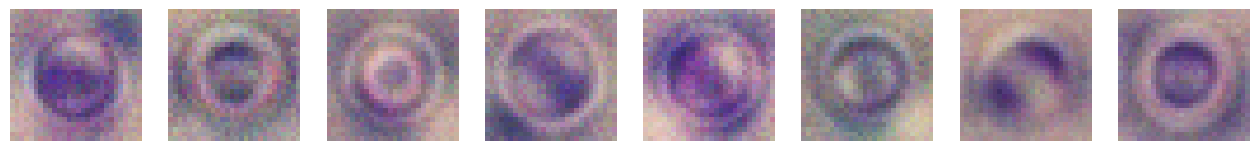

In [45]:
# Create a second VAE
vae_no_kl = VAE(input_dim)

# Train a VAE without KL term
no_kl_train_losses, no_kl_test_losses = train_model(
    vae_no_kl,
    lambda model, x: vae_loss(model, x, beta=0),
    X_train,
    X_test,
    epochs=20
)

# Generate new cells and compare
# Generate 8 random latent vectors
z = torch.randn(8, 16)

# Generate images using the VAE without KL
vae_no_kl.eval()

with torch.no_grad():
    generated_no_kl = vae_no_kl.decoder(z)

# Display generated images
fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for i in range(8):
    image = generated_no_kl[i].reshape(28, 28, 3).numpy()
    axes[i].imshow(image)
    axes[i].axis("off")

plt.show()

*Your answer:* The generated blood cells show more details and different shapes, but also look noisy and grainy without the KL term ß=0. With it thy look smoother but are also blurry and look more similar to another. The reason might be because the KL term encourages the latent space to follow a standard normal distribution, which makes the image generation from random numbers easier. Without KL, the model is more focused on reconstruction, but random image generation becomes less reliable. The KL may help organize the latent space but may also lead to less detailed images..